# 03 · The common shape of the substructure

**Result.**  Across the cloud, the substructure has a common triaxial shape,
leaning prolate: **a1 : a2 : a3 ~ 9 : 2 : 1**.  Its orientation varies from
region to region; its shape varies little.

**How.**  Each of the 46 windows is fitted with an ellipsoidal power law
(notebook 01 for the sample, `mabsf.fitting` for the fit, notebook 02 for
the PSF correction).  This notebook turns the per-window fits into the
numbers quoted in the paper.

**Two descriptions of the anisotropy.**  For S2 = A rho^alpha, the structure
function at a fixed separation r along principal axis i is A (r/a_i)^alpha.
- The **variance ratios** f12 = (a2/a1)^alpha and f23 = (a3/a2)^alpha
  compare how much the brightness varies along two axes *at the same
  separation*, inside the fitted range.  They lie between 0 and 1.
- The **axis ratios** a2/a1 and a3/a2 compare *how far* one must go along two
  axes to see the same variation.  Along the long axis, that distance can be
  far beyond the 0.48 ly window: an extrapolation.

Converting f to an axis ratio raises it to the power 1/alpha ~ 2, which turns
a modestly small f12 into a tiny a2/a1 with an enormous error.  Three windows
are like this ("collapsed" fits, a ratio < 0.02).  The statistics are
therefore done on f12 and f23, where every window has an ordinary error bar,
and the results are converted back to axis ratios to describe the shape.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from mabsf import config as C, preprocess as P, fitting as F, shape as S, plotting
from mabsf.checks import check, targets

plotting.style()
RECOMPUTE = False       # True: refit all windows (`mabsf fit`, ~1-7 min on 8 cores)
cfg = C.Config()
wins = P.sample_windows(cfg)
if RECOMPUTE or not all(os.path.exists(F.fit_path(r, c, cfg)) for r, c in wins):
    F.fit_windows(wins, cfg, procs=8)
summ, k = S.summary(cfg)
k[['row', 'col', 'a2a1', 'a3a2', 'alpha', 'incl', 'f12', 'se_f12', 'f23', 'se_f23', 'collapsed']].round(3).head(8)

,row,col,a2a1,a3a2,alpha,incl,f12,se_f12,f23,se_f23,collapsed
0,1414,1192,0.151,0.394,0.437,45.830,0.438,0.318,0.665,0.076,False
1,1414,1342,0.390,0.533,0.621,41.718,0.557,0.196,0.677,0.052,False
2,1564,1192,0.113,0.537,0.714,39.437,0.211,0.361,0.641,0.150,False
3,1564,1342,0.295,0.441,0.570,50.462,0.499,0.185,0.627,0.152,False
4,1564,1492,0.197,0.589,0.565,69.992,0.400,0.493,0.741,0.105,False
5,1714,1492,0.160,0.555,0.499,65.268,0.401,0.180,0.746,0.053,False
6,1714,1642,0.173,0.808,0.503,75.338,0.413,0.094,0.898,0.147,False
7,1714,1792,0.195,0.712,0.579,83.752,0.388,0.055,0.821,0.124,False


## 1. Why the axis ratio "collapses" and the variance ratio does not

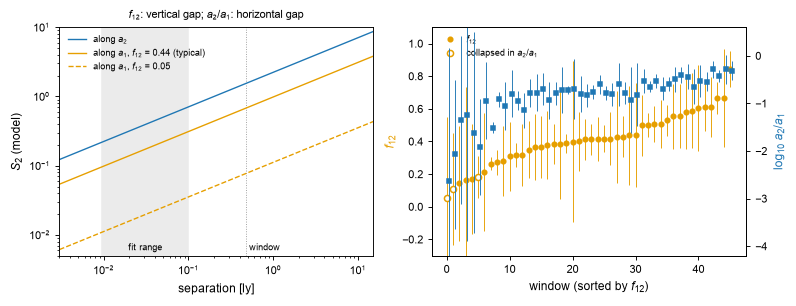

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(plotting.W_IN, 2.8))
a = axs[0]
r = np.logspace(-2.6, 1.2, 300); al, a2 = 0.5, 0.2
S2 = lambda r, aa: (r / aa) ** al
a.axvspan(0.0096, cfg.rcut, color='0.92'); a.axvline(0.48, color='0.6', lw=0.6, ls=':')
a.text(0.031, 0.006, 'fit range', ha='center', fontsize=6); a.text(0.52, 0.006, 'window', fontsize=6)
a.loglog(r, S2(r, a2), color='C0', label='along $a_2$')
a.loglog(r, S2(r, a2 / 0.44 ** (1 / al)), color=plotting.C_WIN, label='along $a_1$, $f_{12}$ = 0.44 (typical)')
a.loglog(r, S2(r, a2 / 0.05 ** (1 / al)), '--', color=plotting.C_WIN, label='along $a_1$, $f_{12}$ = 0.05')
a.set_xlim(0.003, 15); a.set_ylim(5e-3, 10); a.set_xlabel('separation [ly]'); a.set_ylabel('$S_2$ (model)')
a.legend(fontsize=6, loc='upper left')
a.set_title('$f_{12}$: vertical gap; $a_2/a_1$: horizontal gap', fontsize=7)
b = axs[1]
o = np.argsort(k.f12.values); ks = k.iloc[o]; x = np.arange(len(ks)); u = ks.collapsed.values
b.errorbar(x, ks.f12, ks.se_f12, fmt='none', ecolor=plotting.C_WIN, elinewidth=0.6)
b.plot(x[~u], ks.f12[~u], 'o', ms=3, color=plotting.C_WIN, label='$f_{12}$')
b.plot(x[u], ks.f12[u], 'o', ms=4, mfc='w', mec=plotting.C_WIN, label='collapsed in $a_2/a_1$')
b2 = b.twinx(); b2.spines['right'].set_visible(True)
b2.errorbar(x + 0.3, np.log10(ks.a2a1), ks.se_l12, fmt='none', ecolor='C0', elinewidth=0.6)
b2.plot(x + 0.3, np.log10(ks.a2a1), 's', ms=2.5, color='C0', label='log $a_2/a_1$')
b.set_ylim(-0.3, 1.1); b2.set_ylim(-4.2, 0.6)
b.set_xlabel('window (sorted by $f_{12}$)'); b.set_ylabel('$f_{12}$', color=plotting.C_WIN)
b2.set_ylabel('log$_{10}$ $a_2/a_1$', color='C0')
b.legend(loc='upper left', fontsize=6)
fig.tight_layout()

The three collapsed windows sit at the low end of a continuous f12
distribution, with ordinary errors (~0.1).  In log a2/a1 the same windows have
errors of 1-3 dex.

## 2. The common shape and its spread (claims C7, C12)

The common value and intrinsic (window-to-window) scatter of f12 and f23 are
fitted by maximum likelihood, x_i ~ N(mu, s_i^2 + sigma^2), with s_i the
jackknife error of each window.  Errors on sigma come from a bootstrap over
windows.

In [3]:
vr = summ['variance_ratio']
pd.DataFrame({
    'common value': [vr['f12'], vr['f23']],
    'intrinsic scatter': [vr['sig_f12'], vr['sig_f23']],
    'scatter 16-84%': [vr['sig_f12_68'], vr['sig_f23_68']],
    'scatter 95% upper': [vr['sig_f12_95'], vr['sig_f23_95']],
    'p (scatter = 0)': [vr['p0_f12'], vr['p0_f23']],
}, index=['f12 (long / middle)', 'f23 (middle / short)']).round(3)

,common value,intrinsic scatter,scatter 16-84%,scatter 95% upper,p (scatter = 0)
f12 (long / middle),0.429,0.090,"[0.05069997394158838, 0.1099691397241894]",0.135,0.001
f23 (middle / short),0.748,0.052,"[0.032907747716457776, 0.06261212041074347]",0.074,0.090


In words: at separations below 0.1 ly, the brightness varies 1/f12 ~ 2.3 times
less (in variance) along the long axis than along the middle one, and
1/f23 ~ 1.3 times less along the middle than along the short axis.

**In axis-ratio language**, converting at the median slope alpha:

In [4]:
am = summ['median_alpha']
sp = {q: summ['spread_dex_' + q] for q in ('a2a1', 'a3a2')}
fac = lambda d: 10 ** d
print('median alpha = %.2f' % am)
print('common shape: a2/a1 = %.3f, a3/a2 = %.3f  ->  a1 : a2 : a3 = %.1f : %.1f : 1'
      % (summ['common_a2a1'], summ['common_a3a2'], 1 / (summ['common_a2a1'] * summ['common_a3a2']), 1 / summ['common_a3a2']))
print('spread in a2/a1: factor %.2f (95%%: < %.2f) at one alpha; %.2f (< %.2f) with each window\'s alpha'
      % tuple(fac(sp['a2a1'][x]) for x in ('single_alpha', 'single_alpha_95', 'window_alpha', 'window_alpha_95')))
print('spread in a3/a2: %.0f%% (95%%: < %.0f%%) at one alpha; %.0f%% (< %.0f%%) with each window\'s alpha'
      % tuple(100 * (fac(sp['a3a2'][x]) - 1) for x in ('single_alpha', 'single_alpha_95', 'window_alpha', 'window_alpha_95')))

median alpha = 0.51
common shape: a2/a1 = 0.191, a3/a2 = 0.566  ->  a1 : a2 : a3 = 9.3 : 1.8 : 1
spread in a2/a1: factor 1.53 (95%: < 1.91) at one alpha; 1.71 (< 2.09) with each window's alpha
spread in a3/a2: 15% (95%: < 22%) at one alpha; 19% (< 25%) with each window's alpha


The per-window-alpha version is an upper bracket, because part of the slope
spread is measurement noise.  The paper quotes the range: **elongation a2/a1
varies between regions by a factor of ~1.5-1.7 (< ~2 at 95%), flattening
a3/a2 by ~15-20% (< ~25%)**.

For reference, the same statistics computed directly in log axis ratios (the
paper's first form) give a similar common shape, but their scatter estimate
depends strongly on how the collapsed windows are handled (notebook 06):

In [5]:
pd.Series({q: summ[q] for q in ('C7_common_a2a1', 'C7_common_a3a2', 'C12_sigint_a2a1', 'C12_sigint_a3a2',
                                'C12_p_zero_a2a1', 'C12_p_zero_a3a2')}).round(4)

C7_common_a2a1     0.2263
C7_common_a3a2     0.5721
C12_sigint_a2a1    0.0933
C12_sigint_a3a2    0.0703
C12_p_zero_a2a1    0.4386
C12_p_zero_a3a2    0.0080
dtype: float64

## 3. Windows with an unbounded long axis (claim C13)

For the three collapsed windows the variation along the long axis is too
small to measure within the window.  Their 2-sigma upper limit on a2/a1 is
(f12 + 2 se)^(1/alpha):

In [6]:
ul = S.upper_limits(k)
pd.DataFrame([dict(window=rc, region1=(rc == S.R1_TILE), f12=k.set_index(['row', 'col']).f12[rc],
                   se_f12=k.set_index(['row', 'col']).se_f12[rc], alpha=k.set_index(['row', 'col']).alpha[rc],
                   a2a1_upper_2sigma=v) for rc, v in ul.items()]).round(3)

,window,region1,f12,se_f12,alpha,a2a1_upper_2sigma
0,"(1864, 892)",False,0.051,0.497,0.490,1.000
1,"(1864, 2092)",True,0.182,0.128,0.387,0.118
2,"(2014, 1942)",False,0.108,0.344,0.467,0.614


Only Region 1 gives a useful limit (a2/a1 < 0.12); the other two are
consistent with the common shape.

## 4. Triaxial, leaning prolate; not isotropic (claims C10, C11)

In [7]:
pd.Series(dict(
    windows_prolate_f12_lt_f23=summ['n_prolate_f'],
    windows_excluding_isotropy_2sigma=summ['n_exclude_isotropy_2sig'],
    n=len(k),
    prolateness_dex=summ['C11_prolate_dex'],
    prolateness_significance_sigma=summ['C11_prolate_sigma'],
)).round(3)

windows_prolate_f12_lt_f23           43.000
windows_excluding_isotropy_2sigma    44.000
n                                    46.000
prolateness_dex                       0.432
prolateness_significance_sigma        7.586
dtype: float64

f12 < f23 is the same condition as a3/a2 > a2/a1 (for one alpha): the two
short axes are closer to each other than the middle axis is to the long one.

## 5. One shape, many orientations (claims C7c, C8)

If all windows share one 3D shape, the anisotropy seen in the echo plane
should depend on how the long axis is oriented: a long axis lying in the plane
gives an elongated in-plane slice; one tilted toward W gives a round slice.

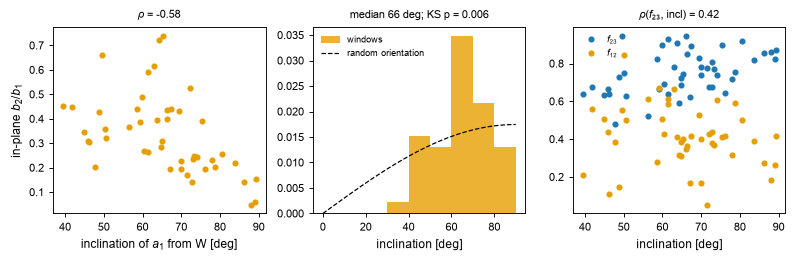

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(plotting.W_IN, 2.4))
axs[0].plot(k.incl, k.b2b1_2d, 'o', ms=3, color=plotting.C_WIN)
axs[0].set_xlabel('inclination of $a_1$ from W [deg]'); axs[0].set_ylabel('in-plane $b_2/b_1$')
axs[0].set_title(r'$\rho$ = %.2f' % summ['C7_rho_incl_b2b1'], fontsize=7)
th = np.linspace(0, 90, 200)
axs[1].hist(k.incl, bins=np.arange(0, 91, 10), color=plotting.C_WIN, alpha=0.8, density=True, label='windows')
axs[1].plot(th, np.sin(np.radians(th)) * np.pi / 180, 'k--', lw=0.8, label='random orientation')
axs[1].set_xlabel('inclination [deg]'); axs[1].legend(fontsize=6)
axs[1].set_title('median %.0f deg; KS p = %.3f' % (summ['C8_median_incl'], summ['C8_ks_p']), fontsize=7)
axs[2].plot(k.incl, k.f23, 'o', ms=3, color='C0', label='$f_{23}$')
axs[2].plot(k.incl, k.f12, 'o', ms=3, color=plotting.C_WIN, label='$f_{12}$')
axs[2].set_xlabel('inclination [deg]'); axs[2].legend(fontsize=6)
axs[2].set_title(r'$\rho(f_{23}$, incl) = %.2f' % summ['rho_f23_incl'], fontsize=7)
fig.tight_layout()

* The in-plane axis ratio follows the inclination as one shape predicts.
* Long axes are spread over a wide range of inclinations, but concentrated
  nearer the echo plane than random orientations would be.
* f23 correlates with inclination, so part of its small scatter is viewing
  geometry; f12 does not.

## 6. Checks against the original analysis

Both calibrations are checked: 'dedup' (this package's default) and
'published' (the first table, with duplicated synthetic fields; the paper's
first numbers).  The differences between the two are small (f12 0.429 vs
0.437).

In [9]:
for calib, key in (('dedup', 'population_dedup'), ('published', 'population_base')):
    s_, k_ = (summ, k) if calib == 'dedup' else S.summary(cfg.replace(calib=calib), n_boot=0)
    t = targets()[key]
    for q in ('f12', 'sig_f12', 'f23', 'sig_f23'):
        check('%s %s' % (calib, q), s_['variance_ratio'][q], t['variance_ratio'][q], rtol=1e-5)
    for q in ('common_a2a1', 'common_a3a2', 'median_alpha', 'n_prolate_f', 'n_exclude_isotropy_2sig', 'rho_f23_incl'):
        check('%s %s' % (calib, q), s_[q], t[q], rtol=1e-6)
    for q in ('C7_common_a2a1', 'C7_common_a3a2', 'C12_sigint_a2a1', 'C12_sigint_a3a2', 'C11_prolate_sigma',
              'C11_frac_prolate', 'C10_n_consistent_isotropic', 'C13_n_collapsed', 'C7_rho_incl_b2b1',
              'C8_median_incl', 'C8_ks_p'):
        check('%s %s' % (calib, q), s_[q], t['claims'][q], rtol=1e-6, atol=1e-9)
    ul_ = S.upper_limits(k_)
    check('%s a2/a1 upper limits' % calib, [ul_[tuple(map(int, x.split('_')))] for x in sorted(t['upper_limits_a2a1'])],
          [t['upper_limits_a2a1'][x] for x in sorted(t['upper_limits_a2a1'])], rtol=1e-6)

ok   dedup f12                                        0.428981  (expected 0.428981)
ok   dedup sig_f12                                    0.0898738  (expected 0.0898738)
ok   dedup f23                                        0.748065  (expected 0.748065)
ok   dedup sig_f23                                    0.0520975  (expected 0.0520975)
ok   dedup common_a2a1                                0.190636  (expected 0.190636)
ok   dedup common_a3a2                                0.566416  (expected 0.566416)
ok   dedup median_alpha                               0.510648  (expected 0.510648)
ok   dedup n_prolate_f                                43  (expected 43)
ok   dedup n_exclude_isotropy_2sig                    44  (expected 44)
ok   dedup rho_f23_incl                               0.423867  (expected 0.423867)
ok   dedup C7_common_a2a1                             0.226311  (expected 0.226311)
ok   dedup C7_common_a3a2                             0.572101  (expected 0.572101)
ok   dedup C